In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
import numpy as np

# Настройка стиля
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# Загрузка данных
df = pd.read_csv('paired_refseq_viral_and_astro_orfs_1_50_batches_results.tsv', sep='\t')
print(f"Загружено {len(df)} строк")
print(f"Колонки: {df.columns.tolist()}")
df.head()

Загружено 143505 строк
Колонки: ['Образец', 'Страна', 'Год', 'Хозяин', 'Длина контига, нт', 'Профиль', 'Идентичность, %', 'Длина выравнивания, амк', 'Мисматчи, амк', 'Начало контига', 'Конец контига', 'Начало референса', 'Конец референса', 'Длина референса, амк', 'Покрытие контига, %', 'Покрытие референса, %', 'E-value', 'Bit-score', 'Бласт хит', 'Инфо', 'Топ 5 профилей']


D:\Users\User\AppData\Local\Temp\ipykernel_11192\3464460909.py:13: DtypeWarning: Columns (0: Страна) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('paired_refseq_viral_and_astro_orfs_1_50_batches_results.tsv', sep='\t')


,Образец,Страна,Год,Хозяин,"Длина контига, нт",Профиль,"Идентичность, %","Длина выравнивания, амк","Мисматчи, амк",Начало контига,...,Начало референса,Конец референса,"Длина референса, амк","Покрытие контига, %","Покрытие референса, %",E-value,Bit-score,Бласт хит,Инфо,Топ 5 профилей
0,ERR14656582,Spain,2021,feces metagenome,459,Caliciviridae|polyprotein_nonstructural,38.5,143,85,39,...,90,232,1084,91.5,13.2,4.140000e-23,97.4,YP_009507248.1 ORF B [Trichoplusia ni TED virus],Contig_ID: k141_11673 | BioProject: PRJEB76898...,Caliciviridae polyprotein;nonstructural (1.62)...
1,ERR14656582,Spain,2021,feces metagenome,813,Poecivirus|polyprotein,30.8,104,72,634,...,1,104,115,38.4,90.4,1.470000e-11,63.2,YP_009909105.1 transposase [Stx2-converting ph...,Contig_ID: k141_11834 | BioProject: PRJEB76898...,Poecivirus polyprotein (1.21); Megrivirus poly...
2,ERR14656582,Spain,2021,feces metagenome,729,Senecavirus|polyprotein,28.7,136,91,401,...,17,149,239,54.7,55.6,1.800000e-08,56.6,YP_010754570.1 hypothetical protein QEH35_gp10...,Contig_ID: k141_13632 | BioProject: PRJEB76898...,Senecavirus polyprotein (1.04)
3,ERR14656582,Spain,2021,feces metagenome,645,Limnipivirus|polyprotein,34.5,113,73,306,...,1,112,157,52.6,71.3,1.590000e-13,68.6,YP_009174618.1 hypothetical protein AR678_gp16...,Contig_ID: k141_13810 | BioProject: PRJEB76898...,Limnipivirus polyprotein (1.08)
4,ERR14656582,Spain,2021,feces metagenome,1113,Lagovirus|polyprotein_nonstructural,35.5,279,154,836,...,6,259,312,74.9,81.4,5.350000e-41,149.0,YP_009507576.1 asparagine synthetase A [Hetero...,Contig_ID: k141_14129 | BioProject: PRJEB76898...,Lagovirus polyprotein;nonstructural (1.01); Am...


In [3]:
# Функция для определения, является ли запись астровирусом
def is_astrovirus(blast_hit):
    if pd.isna(blast_hit) or str(blast_hit).strip() == "":
        return False
    hit = str(blast_hit).lower()
    astro_patterns = ['astrovirus', 'astroviridae', 'mamastrovirus', 'avastrovirus', 'bastrovirus']
    for pattern in astro_patterns:
        if re.search(pattern, hit, re.IGNORECASE):
            return True
    return False

# Функция для определения источника
def get_source(blast_hit):
    if pd.isna(blast_hit) or str(blast_hit).strip() == "":
        return "Unknown"
    hit = str(blast_hit)
    if re.match(r'^[A-Z]{2}_', hit) or re.match(r'^NP_', hit):
        return "RefSeq Viral"
    else:
        return "GenBank"

# Функция для подсчета ORFs из топ-5 профилей
def analyze_orf_types(top5_profiles):
    """
    Анализирует топ-5 профилей и определяет, какие ORFs астровируса присутствуют
    Возвращает множество найденных ORF типов
    """
    if pd.isna(top5_profiles) or str(top5_profiles).strip() == "":
        return set()
    
    profiles = str(top5_profiles)
    orf_types = set()
    
    # Разбиваем на отдельные профили
    profile_parts = profiles.split(';')
    
    for part in profile_parts:
        part = part.strip()
        
        # Удаляем все, что в скобках (score_ratio)
        part = re.sub(r'\s*\([^)]*\)', '', part)
        
        # Проверяем, что это астровирус
        is_astro = False
        astro_patterns = ['astroviridae', 'astrovirus', 'mamastrovirus', 'avastrovirus', 'bastrovirus']
        for pattern in astro_patterns:
            if re.search(pattern, part, re.IGNORECASE):
                is_astro = True
                break
        
        # Если это не астровирус - пропускаем
        if not is_astro:
            continue
        
        # Проверяем наличие 1A
        if re.search(r'1A\b', part, re.IGNORECASE):
            orf_types.add('1A')
        
        # Проверяем наличие 1B (включая 1b_pcr_primer_region)
        if re.search(r'1B\b', part, re.IGNORECASE) or re.search(r'1b_pcr_primer_region', part, re.IGNORECASE):
            orf_types.add('1B')
        
        # Проверяем наличие ORF2 (только у астровирусов)
        if re.search(r'\b2\b', part) or re.search(r'capsid', part, re.IGNORECASE) or re.search(r'VP90', part):
            orf_types.add('2')
        
        # Проверяем наличие 1ab
        if re.search(r'1ab\b', part, re.IGNORECASE):
            if '1A' not in orf_types and '1B' not in orf_types:
                orf_types.add('1A')
    
    return orf_types

# Применяем функции
df['is_astrovirus'] = df['Бласт хит'].apply(is_astrovirus)
df['source'] = df['Бласт хит'].apply(get_source)
df['orf_types'] = df['Топ 5 профилей'].apply(analyze_orf_types)

# Определяем количество ORFs
df['orf_count'] = df['orf_types'].apply(len)

# Классификация контигов
df['genome_type'] = df['orf_types'].apply(
    lambda x: 'Полный геном (3 ORFs)' if x == {'1A', '1B', '2'} 
    else 'Неполный геном' if x 
    else 'Нет ORFs'
)

# Фильтруем только астровирусы
astro_df = df[df['is_astrovirus'] == True].copy()

print(f"Найдено {len(astro_df)} записей, относящихся к астровирусам")
print(f"Это составляет {len(astro_df)/len(df)*100:.2f}% от всех записей")
print(f"Уникальных образцов с астровирусами: {astro_df['Образец'].nunique()}")

Найдено 1455 записей, относящихся к астровирусам
Это составляет 1.01% от всех записей
Уникальных образцов с астровирусами: 210


In [4]:
# 1. Общая статистика по ORFs
print("=" * 80)
print("СТАТИСТИКА ПО АСТРОВИРУСАМ")
print("=" * 80)

# Распределение по типам геномов
genome_counts = astro_df['genome_type'].value_counts()
print("\nРаспределение по типам геномов:")
for gtype, count in genome_counts.items():
    print(f"  {gtype}: {count} ({count/len(astro_df)*100:.2f}%)")

# Распределение по количеству ORFs
orf_count_dist = astro_df['orf_count'].value_counts().sort_index()
print("\nРаспределение по количеству ORFs:")
for count, num in orf_count_dist.items():
    print(f"  {count} ORF: {num} ({num/len(astro_df)*100:.2f}%)")

# Типы ORFs
all_orf_types = []
for orf_set in astro_df['orf_types']:
    all_orf_types.extend(orf_set)
orf_type_counts = Counter(all_orf_types)
print("\nТипы ORFs:")
for orf_type, count in orf_type_counts.most_common():
    print(f"  {orf_type}: {count} ({count/len(astro_df)*100:.2f}%)")

СТАТИСТИКА ПО АСТРОВИРУСАМ

Распределение по типам геномов:
  Неполный геном: 1291 (88.73%)
  Нет ORFs: 124 (8.52%)
  Полный геном (3 ORFs): 40 (2.75%)

Распределение по количеству ORFs:
  0 ORF: 124 (8.52%)
  1 ORF: 1186 (81.51%)
  2 ORF: 105 (7.22%)
  3 ORF: 40 (2.75%)

Типы ORFs:
  1A: 716 (49.21%)
  1B: 459 (31.55%)
  2: 341 (23.44%)


In [5]:
# 2. Анализ полных геномов (только 1A+1B+2) с фильтром длины >= 5000 нт
print("\n" + "=" * 80)
print("АНАЛИЗ ПОЛНЫХ ГЕНОМОВ (1A + 1B + 2, длина >= 5000 нт)")
print("=" * 80)

# Все полные геномы (3 ORFs)
complete_genomes_all = astro_df[astro_df['genome_type'] == 'Полный геном (3 ORFs)'].copy()

# Полные геномы с длиной >= 5000 нт
complete_genomes = complete_genomes_all[complete_genomes_all['Длина контига, нт'] >= 5000].copy()

print(f"\nВсего полных геномов (3 ORFs): {len(complete_genomes_all)}")
print(f"Полных геномов с длиной >= 5000 нт: {len(complete_genomes)}")
print(f"Это {len(complete_genomes)/len(complete_genomes_all)*100:.2f}% от всех полных геномов")
print(f"Это {len(complete_genomes)/len(astro_df)*100:.2f}% от всех астровирусных контигов")

# Отбракованные по длине
rejected_by_length = complete_genomes_all[complete_genomes_all['Длина контига, нт'] < 5000]
if len(rejected_by_length) > 0:
    print(f"\nОтбраковано по длине (< 5000 нт): {len(rejected_by_length)}")
    print(f"Длины отбракованных: {rejected_by_length['Длина контига, нт'].min()} - {rejected_by_length['Длина контига, нт'].max()} нт")

# Источники для полных геномов
complete_by_source = complete_genomes['source'].value_counts()
print("\nИсточники полных геномов (>= 5000 нт):")
for source, count in complete_by_source.items():
    print(f"  {source}: {count} ({count/len(complete_genomes)*100:.2f}%)")

# Длины контигов
print(f"\nДлины полных геномов (>= 5000 нт):")
print(f"  Средняя: {complete_genomes['Длина контига, нт'].mean():.0f} нт")
print(f"  Медианная: {complete_genomes['Длина контига, нт'].median():.0f} нт")
print(f"  Минимальная: {complete_genomes['Длина контига, нт'].min()} нт")
print(f"  Максимальная: {complete_genomes['Длина контига, нт'].max()} нт")


АНАЛИЗ ПОЛНЫХ ГЕНОМОВ (1A + 1B + 2, длина >= 5000 нт)

Всего полных геномов (3 ORFs): 40
Полных геномов с длиной >= 5000 нт: 36
Это 90.00% от всех полных геномов
Это 2.47% от всех астровирусных контигов

Отбраковано по длине (< 5000 нт): 4
Длины отбракованных: 376 - 3950 нт

Источники полных геномов (>= 5000 нт):
  GenBank: 36 (100.00%)

Длины полных геномов (>= 5000 нт):
  Средняя: 6463 нт
  Медианная: 6579 нт
  Минимальная: 5042 нт
  Максимальная: 7189 нт


In [6]:
# 3. Примеры полных геномов (>= 5000 нт)
print("\n" + "=" * 80)
print("ПРИМЕРЫ ПОЛНЫХ ГЕНОМОВ (3 ORFs: 1A, 1B, 2, длина >= 5000 нт)")
print("=" * 80)

if len(complete_genomes) > 0:
    # Сортируем по длине
    complete_genomes_sorted = complete_genomes.sort_values('Длина контига, нт', ascending=False)
    
    for i, (_, row) in enumerate(complete_genomes_sorted.head(40).iterrows(), 1):
        print(f"\n{i}. Образец: {row['Образец']}")
        print(f"   Длина: {row['Длина контига, нт']} нт")
        print(f"   ORFs: {', '.join(sorted(row['orf_types']))}")
        print(f"   Источник: {row['source']}")
        print(f"   Топ-5: {row['Топ 5 профилей']}")
        print("-" * 60)

# Примеры отбракованных полных геномов (длина < 5000)
print("\n" + "=" * 80)
print("ПРИМЕРЫ ПОЛНЫХ ГЕНОМОВ, ОТБРАКОВАННЫХ ПО ДЛИНЕ (< 5000 нт)")
print("=" * 80)

if len(rejected_by_length) > 0:
    rejected_sorted = rejected_by_length.sort_values('Длина контига, нт', ascending=False)
    for i, (_, row) in enumerate(rejected_sorted.head(5).iterrows(), 1):
        print(f"\n{i}. Образец: {row['Образец']}")
        print(f"   Длина: {row['Длина контига, нт']} нт (< 5000)")
        print(f"   ORFs: {', '.join(sorted(row['orf_types']))}")
        print(f"   Топ-5: {row['Топ 5 профилей'][:150]}...")
        print("-" * 60)


ПРИМЕРЫ ПОЛНЫХ ГЕНОМОВ (3 ORFs: 1A, 1B, 2, длина >= 5000 нт)

1. Образец: SRR22936710
   Длина: 7189 нт
   ORFs: 1A, 1B, 2
   Источник: GenBank
   Топ-5: Astroviridae 1A (52.93); Astroviridae 1B (52.49); Astroviridae 2 (46.59); Astroviridae capsid;VP90 (37.90); Mamastrovirus polyprotein 1ab (30.34)
------------------------------------------------------------

2. Образец: SRR22936808
   Длина: 6881 нт
   ORFs: 1A, 1B, 2
   Источник: GenBank
   Топ-5: Astroviridae 1B (53.87); Astroviridae 1A (52.33); Astroviridae 2 (47.07); Astroviridae capsid;VP90 (37.04); Mamastrovirus polyprotein 1ab (31.44)
------------------------------------------------------------

3. Образец: SRR28250713
   Длина: 6826 нт
   ORFs: 1A, 1B, 2
   Источник: GenBank
   Топ-5: Astroviridae 1A (57.01); Astroviridae 1B (50.50); Astroviridae 2 (37.19); Mamastrovirus polyprotein 1ab (32.49); Astroviridae capsid;VP90 (31.50)
------------------------------------------------------------

4. Образец: ERR3179770
   Длина: 6725

In [7]:
# 4. Распределение по источникам
print("\n" + "=" * 80)
print("ИСТОЧНИКИ БЛАСТ ХИТОВ")
print("=" * 80)

source_counts = astro_df['source'].value_counts()
print("\nРаспределение по источникам (все астровирусы):")
for source, count in source_counts.items():
    print(f"  {source}: {count} ({count/len(astro_df)*100:.2f}%)")

# Сравнение источников для полных и неполных геномов
print("\nСравнение источников:")
complete_source_pct = complete_genomes['source'].value_counts(normalize=True) * 100
incomplete_source_pct = astro_df[astro_df['genome_type'] == 'Неполный геном']['source'].value_counts(normalize=True) * 100

for source in ['GenBank', 'RefSeq Viral']:
    if source in complete_source_pct:
        c_pct = complete_source_pct[source]
    else:
        c_pct = 0
    if source in incomplete_source_pct:
        i_pct = incomplete_source_pct[source]
    else:
        i_pct = 0
    print(f"  {source}: Полные (>=5000) - {c_pct:.1f}%, Неполные - {i_pct:.1f}%")


ИСТОЧНИКИ БЛАСТ ХИТОВ

Распределение по источникам (все астровирусы):
  GenBank: 1407 (96.70%)
  RefSeq Viral: 48 (3.30%)

Сравнение источников:
  GenBank: Полные (>=5000) - 100.0%, Неполные - 98.4%
  RefSeq Viral: Полные (>=5000) - 0.0%, Неполные - 1.6%


D:\Users\User\AppData\Local\Temp\ipykernel_2520\2920771068.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1, 0].boxplot(data_to_plot, labels=['Полные\n(3 ORFs, >=5000)', 'Неполные\n(1-2 ORFs)'],


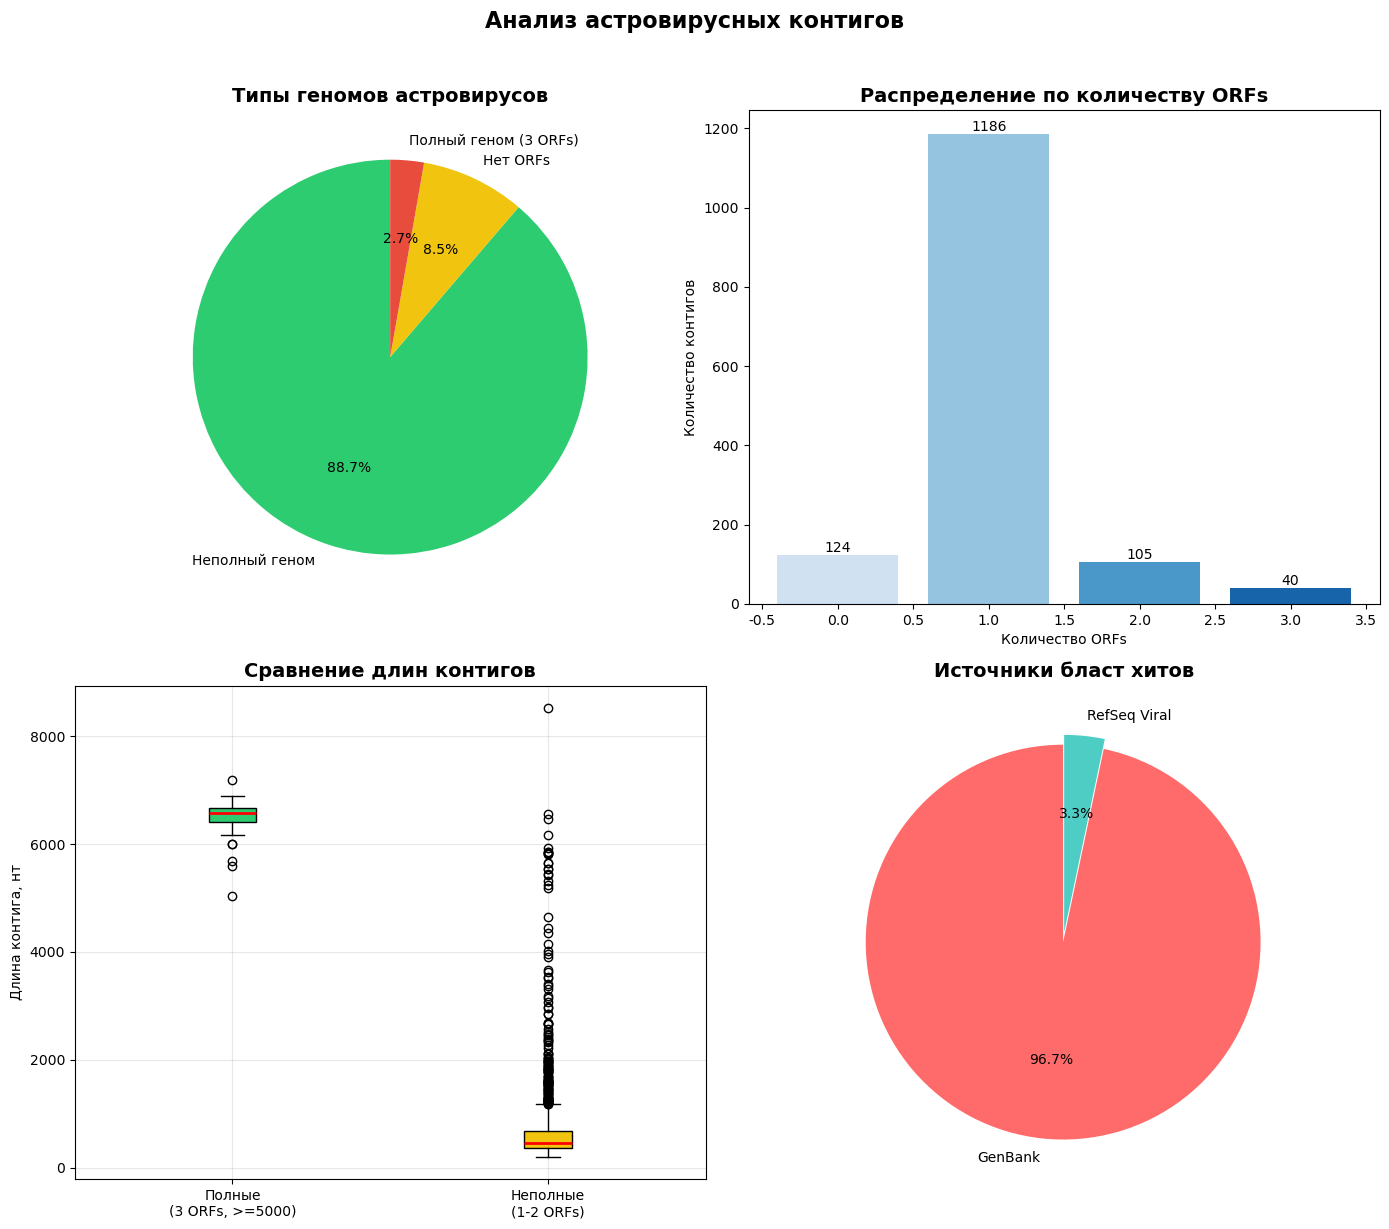

In [8]:
# 5. Визуализация
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# 5.1 Распределение по типам геномов
genome_colors = ['#2ECC71', '#F1C40F', '#E74C3C']
genome_counts_plot = astro_df['genome_type'].value_counts()
axes[0, 0].pie(genome_counts_plot.values, labels=genome_counts_plot.index, 
               autopct='%1.1f%%', colors=genome_colors[:len(genome_counts_plot)], startangle=90)
axes[0, 0].set_title('Типы геномов астровирусов', fontsize=14, fontweight='bold')

# 5.2 Количество ORFs
orf_counts_plot = astro_df['orf_count'].value_counts().sort_index()
bars = axes[0, 1].bar(orf_counts_plot.index, orf_counts_plot.values, 
                      color=sns.color_palette("Blues", len(orf_counts_plot)))
axes[0, 1].set_title('Распределение по количеству ORFs', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Количество ORFs')
axes[0, 1].set_ylabel('Количество контигов')
for bar, val in zip(bars, orf_counts_plot.values):
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                    str(val), ha='center', va='bottom', fontsize=10)

# 5.3 Сравнение длин: полные (>=5000) vs неполные
data_to_plot = [
    complete_genomes['Длина контига, нт'] if len(complete_genomes) > 0 else [],
    astro_df[astro_df['genome_type'] == 'Неполный геном']['Длина контига, нт']
]
bp = axes[1, 0].boxplot(data_to_plot, labels=['Полные\n(3 ORFs, >=5000)', 'Неполные\n(1-2 ORFs)'],
                        patch_artist=True, medianprops=dict(linewidth=2, color='red'))
for patch, color in zip(bp['boxes'], ['#2ECC71', '#F1C40F']):
    patch.set_facecolor(color)
axes[1, 0].set_title('Сравнение длин контигов', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Длина контига, нт')
axes[1, 0].grid(True, alpha=0.3)

# 5.4 Источники
source_counts_plot = astro_df['source'].value_counts()
colors_source = ['#FF6B6B', '#4ECDC4']
axes[1, 1].pie(source_counts_plot.values, labels=source_counts_plot.index, 
               autopct='%1.1f%%', colors=colors_source, startangle=90, explode=(0.05, 0))
axes[1, 1].set_title('Источники бласт хитов', fontsize=14, fontweight='bold')

plt.suptitle('Анализ астровирусных контигов', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

ТОП-10 КОМБИНАЦИЙ ORFs


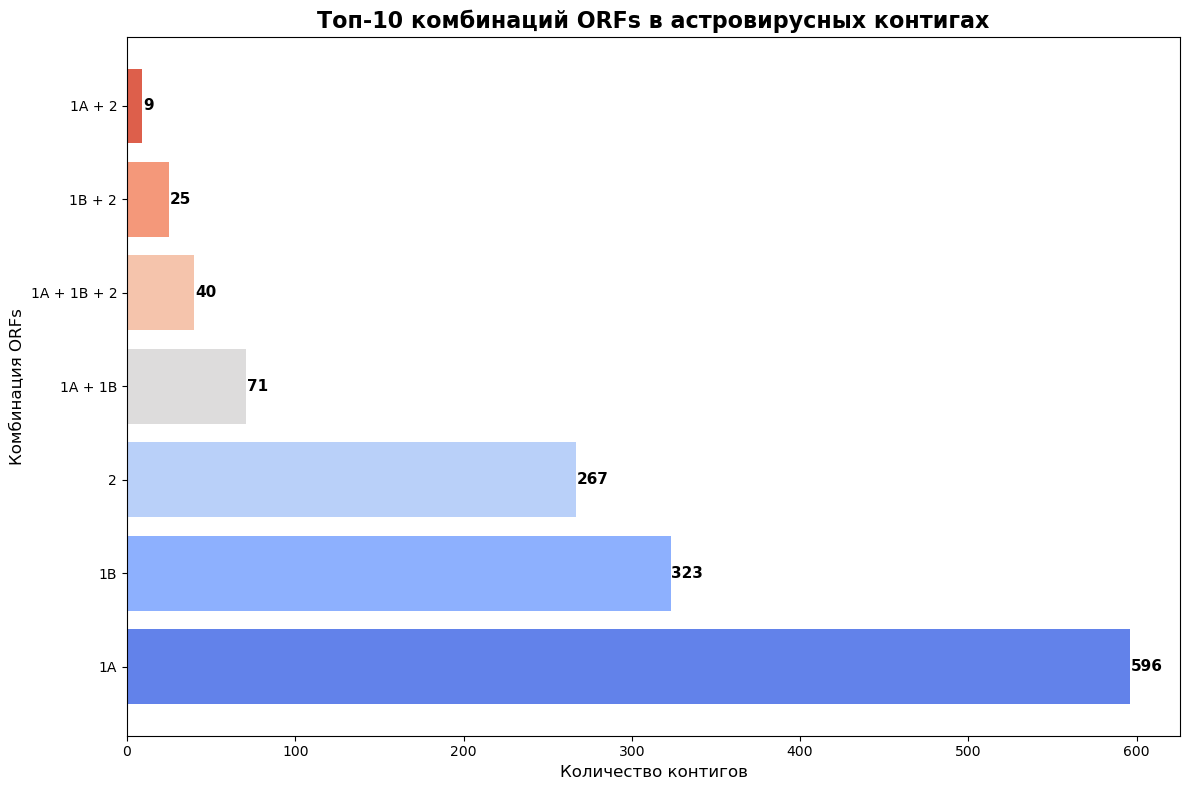


Статистика по комбинациям ORFs:
----------------------------------------
1A                   :  596 (40.96%)
1B                   :  323 (22.20%)
2                    :  267 (18.35%)
1A + 1B              :   71 ( 4.88%)
1A + 1B + 2          :   40 ( 2.75%)
1B + 2               :   25 ( 1.72%)
1A + 2               :    9 ( 0.62%)


In [9]:
# График комбинаций ORFs (топ-10)
print("=" * 80)
print("ТОП-10 КОМБИНАЦИЙ ORFs")
print("=" * 80)

# Подсчет комбинаций ORFs
combo_counts = defaultdict(int)
for orf_set in astro_df['orf_types']:
    if orf_set:
        combo = tuple(sorted(orf_set))
        combo_counts[combo] += 1

# Берем топ-10
top_combos = dict(sorted(combo_counts.items(), key=lambda x: x[1], reverse=True)[:10])
combo_labels = [' + '.join(c) for c in top_combos.keys()]
combo_values = list(top_combos.values())

# Создаем график
plt.figure(figsize=(12, 8))
bars = plt.barh(combo_labels, combo_values, color=sns.color_palette("coolwarm", len(combo_labels)))

# Настройки
plt.title('Топ-10 комбинаций ORFs в астровирусных контигах', fontsize=16, fontweight='bold')
plt.xlabel('Количество контигов', fontsize=12)
plt.ylabel('Комбинация ORFs', fontsize=12)

# Добавляем значения на столбцы
for bar, val in zip(bars, combo_values):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, 
             str(val), ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Выводим статистику
print("\nСтатистика по комбинациям ORFs:")
print("-" * 40)
for combo, count in sorted(combo_counts.items(), key=lambda x: x[1], reverse=True):
    combo_str = ' + '.join(combo)
    percentage = count/len(astro_df)*100
    print(f"{combo_str:20} : {count:4} ({percentage:5.2f}%)")

In [10]:
# 6. Сохранение полных геномов (>= 5000 нт) в Excel
print("\n" + "=" * 80)
print("СОХРАНЕНИЕ ПОЛНЫХ ГЕНОМОВ (3 ORFs: 1A, 1B, 2, длина >= 5000 нт)")
print("=" * 80)

if len(complete_genomes) > 0:
    # Выбираем колонки для сохранения
    columns_to_save = ['Образец', 'Страна', 'Год', 'Хозяин', 'Длина контига, нт', 
                       'Профиль', 'Идентичность, %', 'Длина выравнивания, амк',
                       'Мисматчи, амк', 'Начало контига', 'Конец контига',
                       'Начало референса', 'Конец референса', 'Длина референса, амк',
                       'Покрытие контига, %', 'Покрытие референса, %',
                       'E-value', 'Bit-score', 'Бласт хит', 'Инфо', 'Источник', 
                       'Топ 5 профилей', 'orf_types']
    
    available_cols = [col for col in columns_to_save if col in complete_genomes.columns]
    complete_export = complete_genomes[available_cols].copy()
    
    # Добавляем читаемый список ORFs
    complete_export['ORFs'] = complete_export['orf_types'].apply(lambda x: ', '.join(sorted(x)) if x else '')
    
    # Сортируем по длине
    complete_export = complete_export.sort_values('Длина контига, нт', ascending=False)
    
    # Сохраняем
    output_file = 'complete_genomes_3orfs_min5000.xlsx'
    try:
        with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
            complete_export.to_excel(writer, sheet_name='Полные геномы (>=5000)', index=False)
            
            # Добавляем статистику
            stats_data = {
                'Параметр': [
                    'Всего полных геномов (>=5000)', 
                    'Всего полных геномов (все)',
                    'Отбраковано по длине (<5000)',
                    'Средняя длина (>=5000)',
                    'Медианная длина (>=5000)',
                    'Мин длина (>=5000)',
                    'Макс длина (>=5000)',
                    'GenBank (>=5000)',
                    'RefSeq Viral (>=5000)'
                ],
                'Значение': [
                    len(complete_genomes),
                    len(complete_genomes_all),
                    len(rejected_by_length),
                    f"{complete_genomes['Длина контига, нт'].mean():.0f}",
                    f"{complete_genomes['Длина контига, нт'].median():.0f}",
                    complete_genomes['Длина контига, нт'].min(),
                    complete_genomes['Длина контига, нт'].max(),
                    len(complete_genomes[complete_genomes['source'] == 'GenBank']),
                    len(complete_genomes[complete_genomes['source'] == 'RefSeq Viral'])
                ]
            }
            stats_df = pd.DataFrame(stats_data)
            stats_df.to_excel(writer, sheet_name='Статистика', index=False)
            
            # Добавляем отбракованные по длине
            if len(rejected_by_length) > 0:
                rejected_export = rejected_by_length[available_cols].copy()
                rejected_export['ORFs'] = rejected_export['orf_types'].apply(lambda x: ', '.join(sorted(x)) if x else '')
                rejected_export.to_excel(writer, sheet_name='Отбракованные (<5000)', index=False)
        
        print(f"Файл сохранен: {output_file}")
        print(f"Количество полных геномов (>= 5000 нт): {len(complete_export)}")
        print(f"Количество отбракованных (< 5000 нт): {len(rejected_by_length)}")
        
    except Exception as e:
        print(f"Ошибка при сохранении: {e}")
        # Сохраняем в CSV
        output_csv = 'complete_genomes_3orfs_min5000.csv'
        complete_export.to_csv(output_csv, sep='\t', index=False, encoding='utf-8-sig')
        print(f"Файл сохранен как CSV: {output_csv}")
else:
    print("Нет полных геномов с длиной >= 5000 нт для сохранения")


СОХРАНЕНИЕ ПОЛНЫХ ГЕНОМОВ (3 ORFs: 1A, 1B, 2, длина >= 5000 нт)
Файл сохранен: complete_genomes_3orfs_min5000.xlsx
Количество полных геномов (>= 5000 нт): 36
Количество отбракованных (< 5000 нт): 4


In [11]:
# 7. Итоговый отчет
print("\n" + "=" * 80)
print("ИТОГОВЫЙ ОТЧЕТ")
print("=" * 80)

print(f"\n1. ОБЩАЯ СТАТИСТИКА:")
print(f"   - Всего записей: {len(df)}")
print(f"   - Астровирусных записей: {len(astro_df)}")
print(f"   - Уникальных образцов с астровирусами: {astro_df['Образец'].nunique()}")

print(f"\n2. ПОЛНЫЕ ГЕНОМЫ (1A+1B+2):")
print(f"   - Всего: {len(complete_genomes_all)}")
print(f"   - С длиной >= 5000 нт: {len(complete_genomes)}")
print(f"   - Отбраковано по длине (< 5000): {len(rejected_by_length)}")
print(f"   - Процент от всех астровирусов (>=5000): {len(complete_genomes)/len(astro_df)*100:.2f}%")

if len(complete_genomes) > 0:
    print(f"\n3. ДЛИНЫ ПОЛНЫХ ГЕНОМОВ (>= 5000):")
    print(f"   - Средняя: {complete_genomes['Длина контига, нт'].mean():.0f} нт")
    print(f"   - Медианная: {complete_genomes['Длина контига, нт'].median():.0f} нт")
    print(f"   - Диапазон: {complete_genomes['Длина контига, нт'].min()} - {complete_genomes['Длина контига, нт'].max()} нт")

print(f"\n4. НЕПОЛНЫЕ ГЕНОМЫ:")
print(f"   - С 2 ORFs: {len(astro_df[astro_df['orf_count'] == 2])}")
print(f"   - С 1 ORF: {len(astro_df[astro_df['orf_count'] == 1])}")
print(f"   - Без ORFs: {len(astro_df[astro_df['genome_type'] == 'Нет ORFs'])}")

print(f"\n5. ИСТОЧНИКИ:")
for source, count in source_counts.items():
    print(f"   - {source}: {count} ({count/len(astro_df)*100:.2f}%)")

if len(complete_genomes) > 0:
    print(f"\n6. ИСТОЧНИКИ ПОЛНЫХ ГЕНОМОВ (>= 5000):")
    for source, count in complete_genomes['source'].value_counts().items():
        print(f"   - {source}: {count} ({count/len(complete_genomes)*100:.2f}%)")

print("\n" + "=" * 80)
print("АНАЛИЗ ЗАВЕРШЕН")
print("=" * 80)


ИТОГОВЫЙ ОТЧЕТ

1. ОБЩАЯ СТАТИСТИКА:
   - Всего записей: 143505
   - Астровирусных записей: 1455
   - Уникальных образцов с астровирусами: 210

2. ПОЛНЫЕ ГЕНОМЫ (1A+1B+2):
   - Всего: 40
   - С длиной >= 5000 нт: 36
   - Отбраковано по длине (< 5000): 4
   - Процент от всех астровирусов (>=5000): 2.47%

3. ДЛИНЫ ПОЛНЫХ ГЕНОМОВ (>= 5000):
   - Средняя: 6463 нт
   - Медианная: 6579 нт
   - Диапазон: 5042 - 7189 нт

4. НЕПОЛНЫЕ ГЕНОМЫ:
   - С 2 ORFs: 105
   - С 1 ORF: 1186
   - Без ORFs: 124

5. ИСТОЧНИКИ:
   - GenBank: 1407 (96.70%)
   - RefSeq Viral: 48 (3.30%)

6. ИСТОЧНИКИ ПОЛНЫХ ГЕНОМОВ (>= 5000):
   - GenBank: 36 (100.00%)

АНАЛИЗ ЗАВЕРШЕН
